# Chen 2024 data exploration

1. **Task and stimuli**: what the mouse hears and does on each trial, and the photoinhibition.
2. **Chen 2024 overview**: the DANDI release, which mice, which files, what we kept.
3. **Extracting stats from files**: how each spreadsheet number is computed (subjects, trials, neurons, length, sizes).
4. **Figures**: probes in the brain, neurons per session, firing rates, trials per session, trials by condition,
   trials × neurons, regions, raster.

Data: on HAL at `~/ismael/chen2024/data/nwb_slim` (every NWB of DANDI 000363 without its raw voltage and raw video,
copied by `data/chen2024/chen_download.py`). `data/chen2024/chen_extract.py` reduces it there to the small tables in
`data/chen2024/tables/`, which this notebook reads.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

here = Path.cwd().resolve()
REPO = here
for candidate in [here, *here.parents]:
    if (candidate / "src" / "ladys").is_dir() or (candidate / "data" / "chen2024" / "tables").exists():
        REPO = candidate
        break
TABLES = REPO / "data" / "chen2024" / "tables"
FIGURE_DIR = REPO / "tutorials" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert TABLES.exists(), f"Expected extracted tables at {TABLES}; see data/chen2024/README.md"
GB = 1e9
DANDI_BYTES = 65_700_262_850_745  # dandiset 000363 version 0.231012.2129, all 174 assets

sessions = pd.read_parquet(TABLES / "sessions.parquet")
probes = pd.read_parquet(TABLES / "probes.parquet")
units = pd.read_parquet(TABLES / "units.parquet")
trials = pd.read_parquet(TABLES / "trials.parquet")
good = units[units.classification == "good"]
span = trials.groupby("session").agg(trial_start=("start_time", "min"), trial_end=("stop_time", "max"))
sessions = sessions.join(span, on="session")
sessions["trial_min"] = (sessions.trial_end - sessions.trial_start) / 60
# time with spikes: each trial's duration, cut at the session's last spike (spikes exist only inside trials)
last = trials.session.map(sessions.set_index("session").t_last)
trials["spike_s"] = (np.minimum(trials.stop_time, last) - trials.start_time).clip(lower=0)
sessions["spike_min"] = trials.groupby("session").spike_s.sum().reindex(sessions.session).to_numpy() / 60
good = good.assign(rate_hz=good.n_spikes / good.session.map(sessions.set_index("session").spike_min * 60))
cols = ["subject", "probes", "units", "good_units", "trials", "spike_min", "length_min", "trial_min", "tracking_hz"]
display(sessions[cols].describe().round(1))

,probes,units,good_units,trials,spike_min,length_min,trial_min,tracking_hz
count,174.0,174.0,174.0,174.0,174.0,174.0,174.0,174.0
mean,3.8,1564.5,399.2,545.9,44.9,63.6,65.1,294.1
std,0.7,546.7,162.8,89.4,9.3,12.7,11.8,0.0
min,2.0,493.0,0.0,264.0,11.4,16.1,30.6,294.1
25%,3.0,1149.8,279.0,500.0,39.9,57.9,58.3,294.1
50%,4.0,1571.5,390.0,534.0,43.9,62.8,63.0,294.1
75%,4.0,1955.8,497.8,600.8,50.9,72.4,73.1,294.1
max,5.0,3191.0,923.0,800.0,74.4,95.5,111.6,294.1


## 1. Task and stimuli

Paper Fig. 1A–C (Chen et al. 2024, author manuscript):
- **A**: the trial.
- **B**: the rig: 2–5 Neuropixels probes, lick ports, two cameras, photoinhibition light on ALM.
- **C**: the side and bottom camera views, with tracked jaw, nose and tongue points.

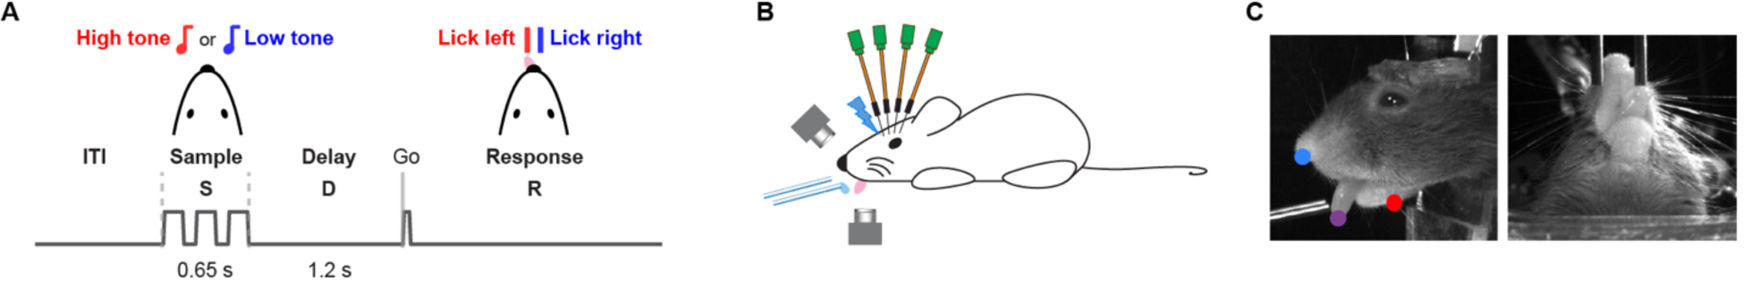

In [2]:
display(Image(filename=str(FIGURE_DIR / "chen_paper_task.png"), width=900))

**One trial** (memory-guided directional licking, "audio delay"). Every session runs this one task.

1. **Sample (0.65 s)**: a tone beeps three times (150 ms each, 100 ms apart).
   - **High tone (12 kHz) = lick left**. **Low tone (3 kHz) = lick right**.
2. **Delay (1.2 s)**: silence. The mouse must remember the side and hold still.
   - An early lick replays the sample / delay epoch (flagged as `early_lick` in the trials table).
3. **Go cue**: a 0.1 s 6 kHz tone.
4. **Response (1.5 s window)**: the mouse licks the left or right port.
   - Correct port: a drop of water (**hit**).
   - Wrong port: a 1–3 s timeout (**miss**).
   - No lick: **ignore**.
   - The trial ends after 1.5 s without licking. Then a 250 ms inter-trial interval follows.

**Photoinhibition**
- In 17 VGAT-ChR2 mice, on ~25 % of trials (randomly interleaved).
- Blue light silences the left, right or both ALM hemispheres for the last 0.5 s of the delay.
- The NWB trials table says which trials (power 5.5 mW, 0.5 s), not which hemisphere.

**Conditions**
- Instruction (left / right) × photoinhibition (off / on): 4 conditions.
- Outcome, early lick, lick times and jaw / nose / tongue tracking record what the mouse did.

Below, from the trials table:
- trials per condition;
- the outcome mix in each condition;
- trial length (`stop_time` − `start_time`; this includes the replays after early licks).

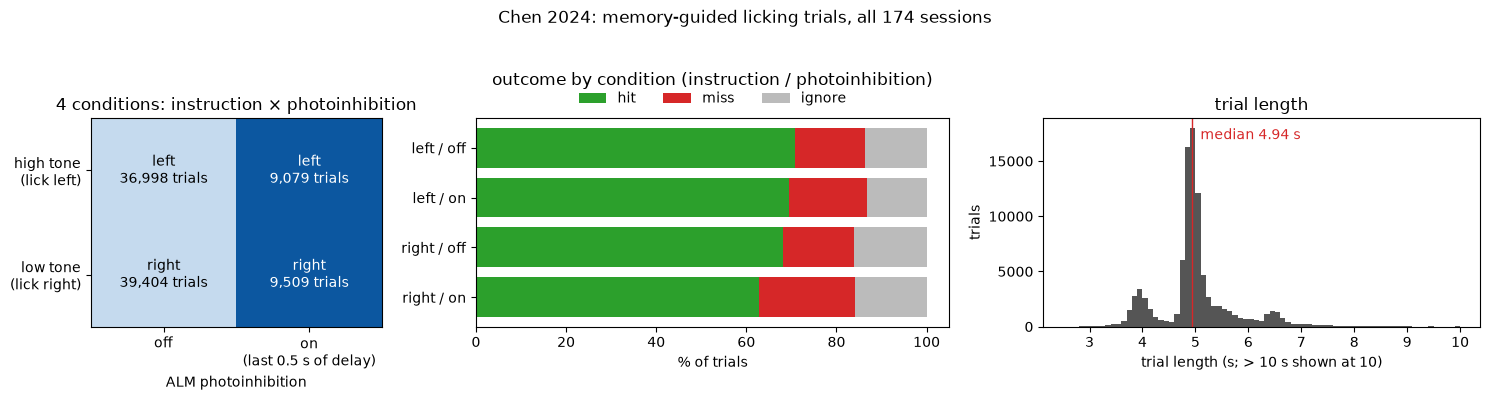

outcome                          hit  miss  ignore  trials
trial_instruction photostim                               
left              no photostim  70.7  15.7    13.6   36998
                  photostim     69.5  17.3    13.2    9079
right             no photostim  68.0  15.8    16.1   39404
                  photostim     62.7  21.4    15.8    9509

In [3]:
trials["photostim"] = np.where(trials.photostim_power != "N/A", "photostim", "no photostim")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [0.8, 1.3, 1.2]})
grid = pd.crosstab(trials.trial_instruction, trials.photostim).reindex(index=["left", "right"],
                                                                     columns=["no photostim", "photostim"])
ax = axes[0]
ax.imshow([[0.25, 0.85], [0.25, 0.85]], cmap="Blues", vmin=0, vmax=1, aspect="auto")
for (i, j), n in np.ndenumerate(grid.to_numpy()):
    ax.text(j, i, f"{grid.index[i]}\n{n:,} trials", ha="center", va="center", fontsize=10,
            color="white" if j else "black")
ax.set_xticks([0, 1], ["off", "on\n(last 0.5 s of delay)"])
ax.set_xlabel("ALM photoinhibition")
ax.set_yticks([0, 1], ["high tone\n(lick left)", "low tone\n(lick right)"])
ax.set_title("4 conditions: instruction × photoinhibition")
ax = axes[1]
mix = pd.crosstab([trials.trial_instruction, trials.photostim], trials.outcome, normalize="index")[["hit", "miss", "ignore"]]
left = np.zeros(len(mix))
for col, color in zip(["hit", "miss", "ignore"], ["#2ca02c", "#d62728", "#bbbbbb"]):
    ax.barh(range(len(mix)), mix[col] * 100, left=left, color=color, label=col)
    left += mix[col].to_numpy() * 100
ax.set_yticks(range(len(mix)), [f"{i} / {'on' if p == 'photostim' else 'off'}" for i, p in mix.index])
ax.invert_yaxis()
ax.set_xlabel("% of trials")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("outcome by condition (instruction / photoinhibition)", pad=24)
ax = axes[2]
dur = trials.stop_time - trials.start_time
ax.hist(dur.clip(upper=10), bins=np.arange(2.5, 10.05, 0.1), color="#555555")
ax.axvline(dur.median(), color="#d62728", lw=1)
ax.text(dur.median() + 0.15, ax.get_ylim()[1] * 0.9, f"median {dur.median():.2f} s", color="#d62728")
ax.set_xlabel("trial length (s; > 10 s shown at 10)")
ax.set_ylabel("trials")
ax.set_title("trial length")
fig.suptitle("Chen 2024: memory-guided licking trials, all 174 sessions", y=1.04)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "chen_task.png", dpi=150, bbox_inches="tight")
plt.show()
display((mix * 100).round(1).assign(trials=pd.crosstab([trials.trial_instruction, trials.photostim],
                                                        trials.outcome).sum(axis=1)))

## 2. Chen 2024 overview

- **Release**: DANDI [000363](https://dandiarchive.org/dandiset/000363/0.231012.2129) "Mesoscale Activity Map
  Dataset", version 0.231012.2129.
  - Chen, Nguyen, Li, Svoboda 2023; license **CC0 1.0**.
  - The data of Chen et al. 2024, *Brain-wide neural activity underlying memory-guided movement*, Cell 187:676
    ([10.1016/j.cell.2023.12.035](https://doi.org/10.1016/j.cell.2023.12.035)).
- **One NWB per session**: 174 sessions from 28 mice.
  - **2–5 Neuropixels probes recorded at once**, aimed at ALM and the areas it connects to (striatum, thalamus,
    midbrain, medulla, ...).
- **One task**: memory-guided directional licking ("audio delay"; see section 1).
  - A tone (sample epoch) tells the mouse which side will pay.
  - The mouse waits through a delay, then licks left or right after a go cue.
  - Photoinhibition: on ~25 % of trials in 17 VGAT-ChR2 mice, blue light on GABAergic interneurons silences the
    left, right or both ALM hemispheres for the last 0.5 s of the delay.
  - The trials table says which trials, not which hemisphere.
- **Units**: Kilosort2 clusters.
  - `good` comes from region-specific classifiers trained on manual curation (paper methods).
  - About a quarter of all units are `good`.
- **Behavior**: lick times, task-epoch times, and jaw / nose / tongue positions tracked from a side camera (~294 Hz).

| NWB part | What | Used for |
|---|---|---|
| `units` | sorted units: spike times, QC class (`good` / `unlabelled`), CCF annotation, peak electrode | NEURONS, LENGTH, regions |
| `intervals/trials` | instruction (left / right), outcome (hit / miss / ignore), early lick, photostim, auto / free water | TRIALS, conditions |
| `acquisition/BehavioralEvents` | task-epoch start / stop times, left / right licks, photostim times | behavior labels |
| `acquisition/BehavioralTimeSeries` | jaw, nose, tongue (x, y, likelihood) per camera frame | behavior labels |
| `general/extracellular_ephys` | probes (target, bregma coordinates), electrodes with CCF position | regions, probe figure |
| `acquisition/ElectricalSeries-*` | raw voltage, int16, one per probe | RAW size only (not copied) |
| `acquisition/*side_face*` | face video, one ImageSeries per trial | RAW size only (not copied) |

**Data quirks**
- **Spikes are released only inside trials.**
  - Every spike falls between a trial's `start_time` and `stop_time`.
  - The ~2 s between trials has no spikes (gaps in the raster below).
  - So recorded time is trial time, not first-to-last spike.
- **5 sessions (assets of 0.1–0.3 GB) have no raw voltage or video in DANDI.**
  - In 4 of them, and in the full-size `sub-441666_ses-20190513T144253`, the spikes stop long before the trials
    do (shown below).
  - Those sessions count only the trial time before their last spike.
- **One session (`sub-440958_ses-20190216T162508`) has no QC labels** (stored as NaN), so it has 0 good units.
  - Its 4 probes are also the only ones without electrode CCF positions.

**Checks**
- All 174 assets were copied, and their sizes add up to the dandiset's.
- Units per probe and per session add up.
- The paper reports (the cell below prints the release's numbers):
  - 69,943 good units from 173 sessions and 655 probe insertions;
  - a median of 393 good units per session, 25.9 % of all Kilosort2 units;
  - 476 trials per session on average (130–785).
- The table lists sessions whose last spike comes more than a minute before their last trial ends.

In [4]:
assert len(sessions) == 174 and sessions.source_bytes.sum() == DANDI_BYTES, (len(sessions), sessions.source_bytes.sum())
assert probes.groupby("session").units.sum().reindex(sessions.session).tolist() == sessions.units.tolist()
assert (good.groupby("session").size().reindex(sessions.session, fill_value=0).to_numpy() == sessions.good_units).all()
print(f"good units {sessions.good_units.sum():,} (paper 69,943), sessions with good units {(sessions.good_units > 0).sum()} "
      f"(paper 173), probes {len(probes)} (paper 655), median good units {sessions.good_units.median():.0f} (paper 393), "
      f"good / all {sessions.good_units.sum() / sessions.units.sum():.1%} (paper 25.9 %), trials per session mean "
      f"{sessions.trials.mean():.0f}, range {sessions.trials.min()}–{sessions.trials.max()} (paper 476, 130–785)")
short = sessions[sessions.t_last < sessions.trial_end - 60]
display(short[["session", "trials", "good_units", "spike_min", "trial_min", "source_bytes"]]
        .assign(source_GB=short.source_bytes / GB).drop(columns="source_bytes").round(2))

good units 69,453 (paper 69,943), sessions with good units 173 (paper 173), probes 659 (paper 655), median good units 390 (paper 393), good / all 25.5% (paper 25.9 %), trials per session mean 546, range 264–800 (paper 476, 130–785)


,session,trials,good_units,spike_min,trial_min,source_GB
1,sub-440956_ses-20190208T133600,480,375,12.75,61.82,0.13
3,sub-440956_ses-20190210T155629,582,552,16.61,111.65,0.19
11,sub-440958_ses-20190216T162508,620,0,11.36,78.04,0.16
21,sub-441666_ses-20190513T144253,534,300,43.22,78.67,462.67
28,sub-442571_ses-20190301T140324,501,433,22.67,62.31,0.17


## 3. Extracting stats from files

- **SUBJECTS**: mice (`sub-*`), 28.
- **TRIALS**: every row of `intervals/trials`.
  - This includes all outcomes, early-lick, photostim and auto / free-water trials.
  - The breakdown goes in NOTES.
- **NEURONS**: units with QC class `good` (the units the paper analyzes).
  - The paper's median of 393 per session matches.
  - TOTAL = sum. MEDIAN = per session (all probes of a session are simultaneous).
  - All sorted units go in NOTES.
- **CHANNELS**: `N/A` (sorted units).
- **LENGTH**: time with spikes. This is the summed duration of every trial, cut at its session's last spike.
  - Reason: spikes are released only inside trials.
  - First-to-last spike, which also counts the empty gaps between trials, goes in NOTES.
- **RAW**: the whole dandiset: every NWB, with raw voltage and per-trial face video inside, compressed.
- **BENCHMARK**: what a spiking benchmark needs, at its in-memory size.
  - Kept: good-unit spike times (float64, 8 bytes per spike; unit identity comes from the per-unit index).
  - Kept: the trials table, the behavioral events (epochs, licks, photostim) and the jaw / nose / tongue tracking.
  - Left out: raw voltage, video and non-good units.

In [5]:
raw_bytes = sessions.source_bytes.sum()
spike_bytes = sessions.good_spike_bytes.sum()
beh_bytes = sessions.behavior_bytes.sum()
trial_bytes = sessions.trial_bytes.sum()
benchmark_bytes = spike_bytes + beh_bytes + trial_bytes
summary = pd.Series({
    "subjects": sessions.subject.nunique(), "sessions": len(sessions), "trials": len(trials),
    "total neurons (good)": sessions.good_units.sum(), "median neurons (good)": sessions.good_units.median(),
    "all sorted units": sessions.units.sum(), "length (min)": round(sessions.spike_min.sum(), 1),
    "  first-to-last spike (min)": round(sessions.length_min.sum(), 1),
    "raw (GB)": round(raw_bytes / GB, 3),
    "  raw voltage, uncompressed (GB)": round(sessions.raw_ephys_nominal_bytes.sum() / GB, 1),
    "  face video, uncompressed (GB)": round(sessions.raw_video_nominal_bytes.sum() / GB, 1),
    "benchmark (GB)": round(benchmark_bytes / GB, 3), "  good-unit spikes (GB)": round(spike_bytes / GB, 3),
    "  behaviour events + tracking (GB)": round(beh_bytes / GB, 3), "  trials (GB)": round(trial_bytes / GB, 3)})
display(summary.to_frame("value"))

,value
subjects,28.000
sessions,174.000
trials,94990.000
total neurons (good),69453.000
median neurons (good),390.000
all sorted units,272227.000
length (min),7814.200
first-to-last spike (min),11063.400
raw (GB),65700.263
"raw voltage, uncompressed (GB)",56357.000


## 4. Figures

### Probes in the brain

- Every probe, drawn through its electrodes' CCF positions.
  - `chen_probes.png` is rendered with brainrender outside this notebook, from `electrodes.parquet`.
- The table lists the probe targets written in the NWB.

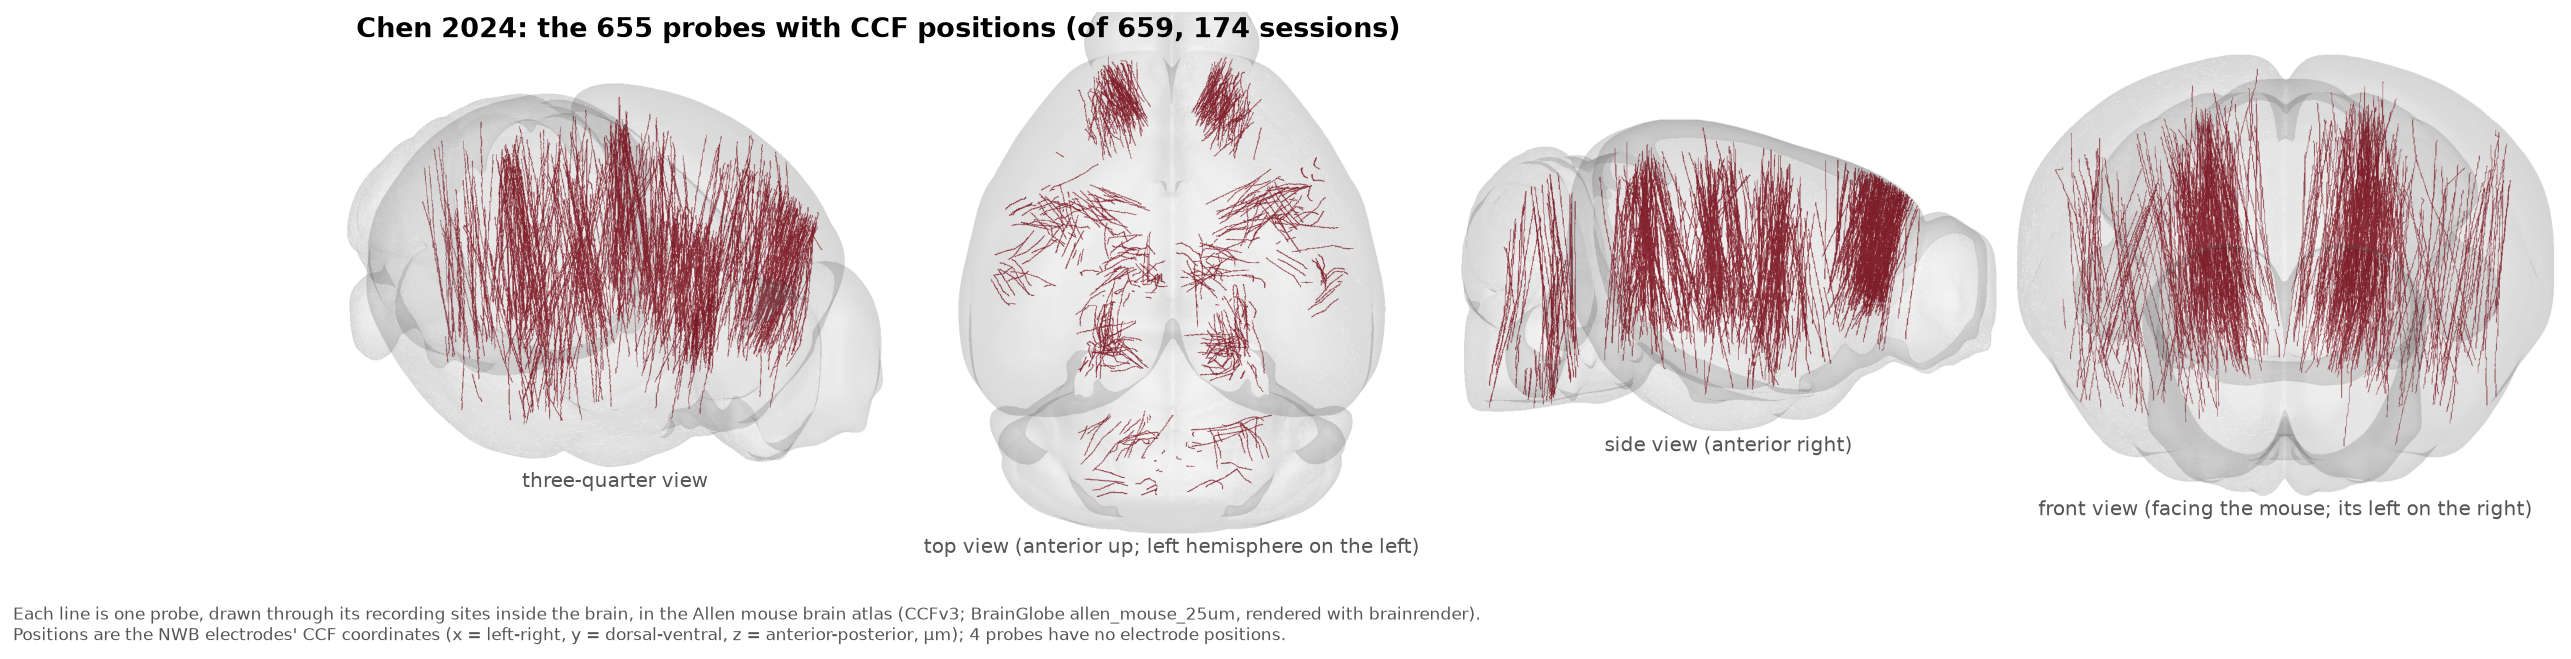

probe target,left ALM,right ALM,left Midbrain,right Midbrain,right Striatum,left Striatum,left Thalamus,right Thalamus,left Medulla,right Medulla,left ECT,right ECT,left BLA,right BLA
probes,108,103,68,68,59,55,51,40,31,27,18,14,9,8


probes per session,2,3,4,5
sessions,2,53,99,20


In [6]:
display(Image(filename=str(FIGURE_DIR / "chen_probes.png")))
display(probes.target.value_counts().rename_axis("probe target").to_frame("probes").T)
display(sessions.probes.value_counts().sort_index().rename_axis("probes per session").to_frame("sessions").T)

### Neurons per session

- Sessions by number of units (sum over probes): all sorted units and good units.
- Separate panels, as in the IBL notebook.

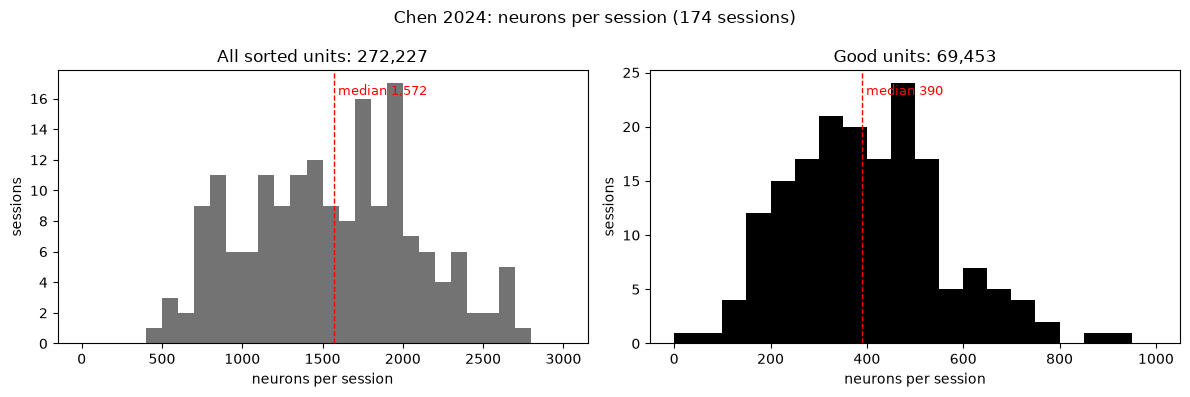

In [7]:
def median_line(ax, values, color="k"):
    m = float(np.median(values))
    ax.axvline(m, color=color, ls="--", lw=1)
    ax.text(m, ax.get_ylim()[1] * 0.95, f" median {m:,.0f}", color=color, va="top", fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, color, name, bins in [(axes[0], "units", "0.45", "All sorted units", np.arange(0, 3100, 100)),
                                   (axes[1], "good_units", "k", "Good units", np.arange(0, 1050, 50))]:
    ax.hist(sessions[col], bins=bins, color=color)
    ax.set(title=f"{name}: {sessions[col].sum():,}", xlabel="neurons per session", ylabel="sessions")
    median_line(ax, sessions[col], "r")
fig.suptitle(f"Chen 2024: neurons per session ({len(sessions)} sessions)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "chen_neurons_per_session.png", dpi=150)
plt.show()

### Firing rates

- One rate per good unit: its spikes over its session's time with spikes (LENGTH above).
- The NWB's own `avg_firing_rate` has almost the same median, so it probably uses trial time too.
- Over first-to-last spike, the rates would be ~30 % lower.

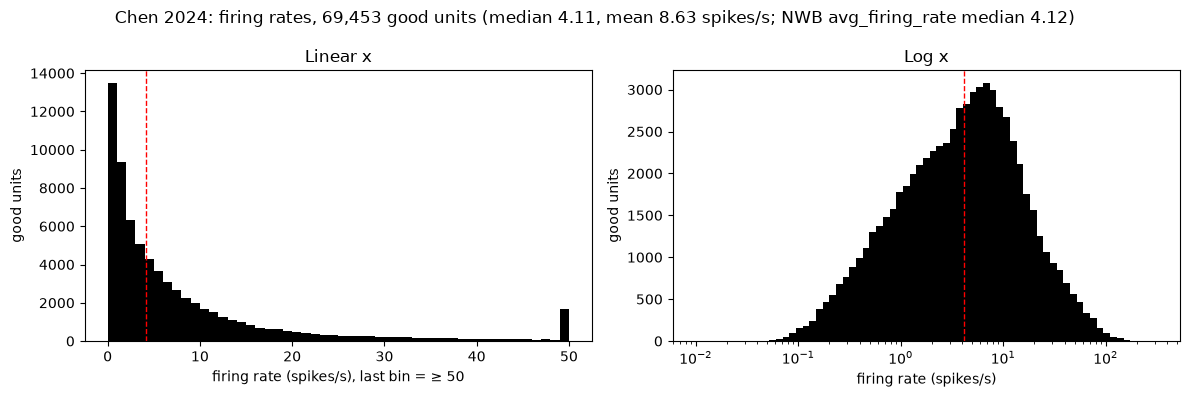

In [8]:
fr = good.rate_hz
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(fr.clip(upper=50), bins=np.arange(0, 51, 1), color="k")
axes[0].set(xlabel="firing rate (spikes/s), last bin = ≥ 50", ylabel="good units", title="Linear x")
axes[1].hist(fr[fr > 0], bins=np.logspace(-2, 2.5, 70), color="k")
axes[1].set(xscale="log", xlabel="firing rate (spikes/s)", ylabel="good units", title="Log x")
for ax in axes:
    ax.axvline(fr.median(), color="r", ls="--", lw=1)
fig.suptitle(f"Chen 2024: firing rates, {len(fr):,} good units (median {fr.median():.2f}, mean {fr.mean():.2f} spikes/s;"
             f" NWB avg_firing_rate median {good.avg_firing_rate.median():.2f})")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "chen_firing_rates.png", dpi=150)
plt.show()

### Trials per session

Sessions by trial count: all trials (filled) and hit trials (outline).

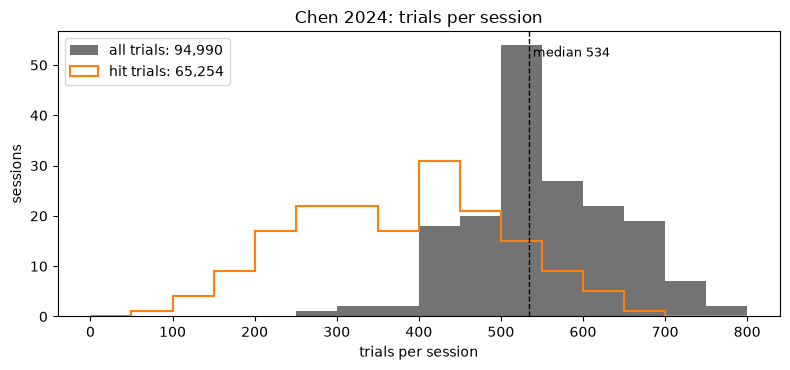

In [9]:
hits = trials[trials.outcome == "hit"].groupby("session").size().reindex(sessions.session, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, sessions.trials.max() + 50, 50)
ax.hist(sessions.trials, bins=bins, color="0.45", label=f"all trials: {sessions.trials.sum():,}")
ax.hist(hits, bins=bins, histtype="step", color="C1", lw=1.5, label=f"hit trials: {hits.sum():,}")
ax.set(xlabel="trials per session", ylabel="sessions", title="Chen 2024: trials per session")
ax.legend()
median_line(ax, sessions.trials)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "chen_trials_per_session.png", dpi=150)
plt.show()

### Trials by condition

- **Instruction**: the side that the tone says will pay (left / right).
- **Photostim**: ALM photoinhibited on that trial (power 5.5 mW and duration 0.5 s in every NWB).
  - Not every session has photostim trials. The line below counts them.
- **Outcome**: hit (licked the instructed side), miss (the other side), ignore (no lick).
- **Early lick**: licked before the go cue.
- **Auto / free water**: reward given without a correct lick.
- **% per session**: median [min – max] over sessions of that category's share of the session's trials.

In [10]:
trials["photostim"] = np.where(trials.photostim_power != "N/A", "photostim", "no photostim")
assert set(trials.photostim_power) <= {"N/A", "5.500"} and set(trials.photostim_duration) <= {"N/A", "0.5000"}


def mix_table(col, order):
    table = pd.crosstab(trials.session, trials[col]).reindex(columns=order, fill_value=0)
    share = table.div(table.sum(axis=1), axis=0) * 100
    return pd.DataFrame({
        "trials": table.sum().to_numpy(),
        "% of trials": (table.sum() / len(trials) * 100).round(1).to_numpy(),
        "% per session": [f"{share[c].median():.1f} [{share[c].min():.1f} – {share[c].max():.1f}]" for c in order],
    }, index=order).rename_axis(col)


trials["water"] = np.select([trials.auto_water.astype(int) > 0, trials.free_water.astype(int) > 0],
                            ["auto water", "free water"], "earned")
for col, order in [("trial_instruction", ["left", "right"]), ("outcome", ["hit", "miss", "ignore"]),
                   ("photostim", ["no photostim", "photostim"]), ("early_lick", ["no early", "early"]),
                   ("water", ["earned", "auto water", "free water"])]:
    display(mix_table(col, order))
display(pd.crosstab([trials.trial_instruction, trials.photostim], trials.outcome, margins=True)[["hit", "miss", "ignore", "All"]])
print(f"sessions with photostim trials: {(trials.groupby('session').photostim.apply(lambda p: (p == 'photostim').any())).sum()}"
      f" of {len(sessions)}")
cond = trials.groupby(["session", "trial_instruction", "photostim"]).size()
ctl = cond.xs("no photostim", level="photostim")
print(f"trials per condition per session (instruction × photostim, conditions the session has): median "
      f"{cond.median():.0f} ({cond.min()}–{cond.max()}); control trials per instruction: median {ctl.median():.0f}")

,trials,% of trials,% per session
trial_instruction,,,
left,46077,48.5,49.5 [13.1 – 79.3]
right,48913,51.5,50.5 [20.7 – 86.9]


,trials,% of trials,% per session
outcome,,,
hit,65254,68.7,71.6 [17.1 – 93.0]
miss,15641,16.5,15.1 [2.4 – 40.7]
ignore,14095,14.8,8.3 [0.0 – 76.9]


,trials,% of trials,% per session
photostim,,,
no photostim,76402,80.4,79.3 [70.6 – 100.0]
photostim,18588,19.6,20.7 [0.0 – 29.4]


,trials,% of trials,% per session
early_lick,,,
no early,84185,88.6,90.6 [63.5 – 100.0]
early,10805,11.4,9.4 [0.0 – 36.5]


,trials,% of trials,% per session
water,,,
earned,91224,96.0,95.4 [86.4 – 100.0]
auto water,1339,1.4,0.6 [0.0 – 13.6]
free water,2427,2.6,3.2 [0.0 – 7.2]


outcome                           hit   miss  ignore    All
trial_instruction photostim                                
left              no photostim  26164   5791    5043  36998
                  photostim      6311   1568    1200   9079
right             no photostim  26814   6245    6345  39404
                  photostim      5965   2037    1507   9509
All                             65254  15641   14095  94990

sessions with photostim trials: 168 of 174
trials per condition per session (instruction × photostim, conditions the session has): median 114 (4–402); control trials per instruction: median 219


### Trials × neurons

- Each cell counts sessions with that many trials (x) and units (y).
- Top: number of sessions. Bottom: % of sessions.
- Columns: all sorted units, good units.

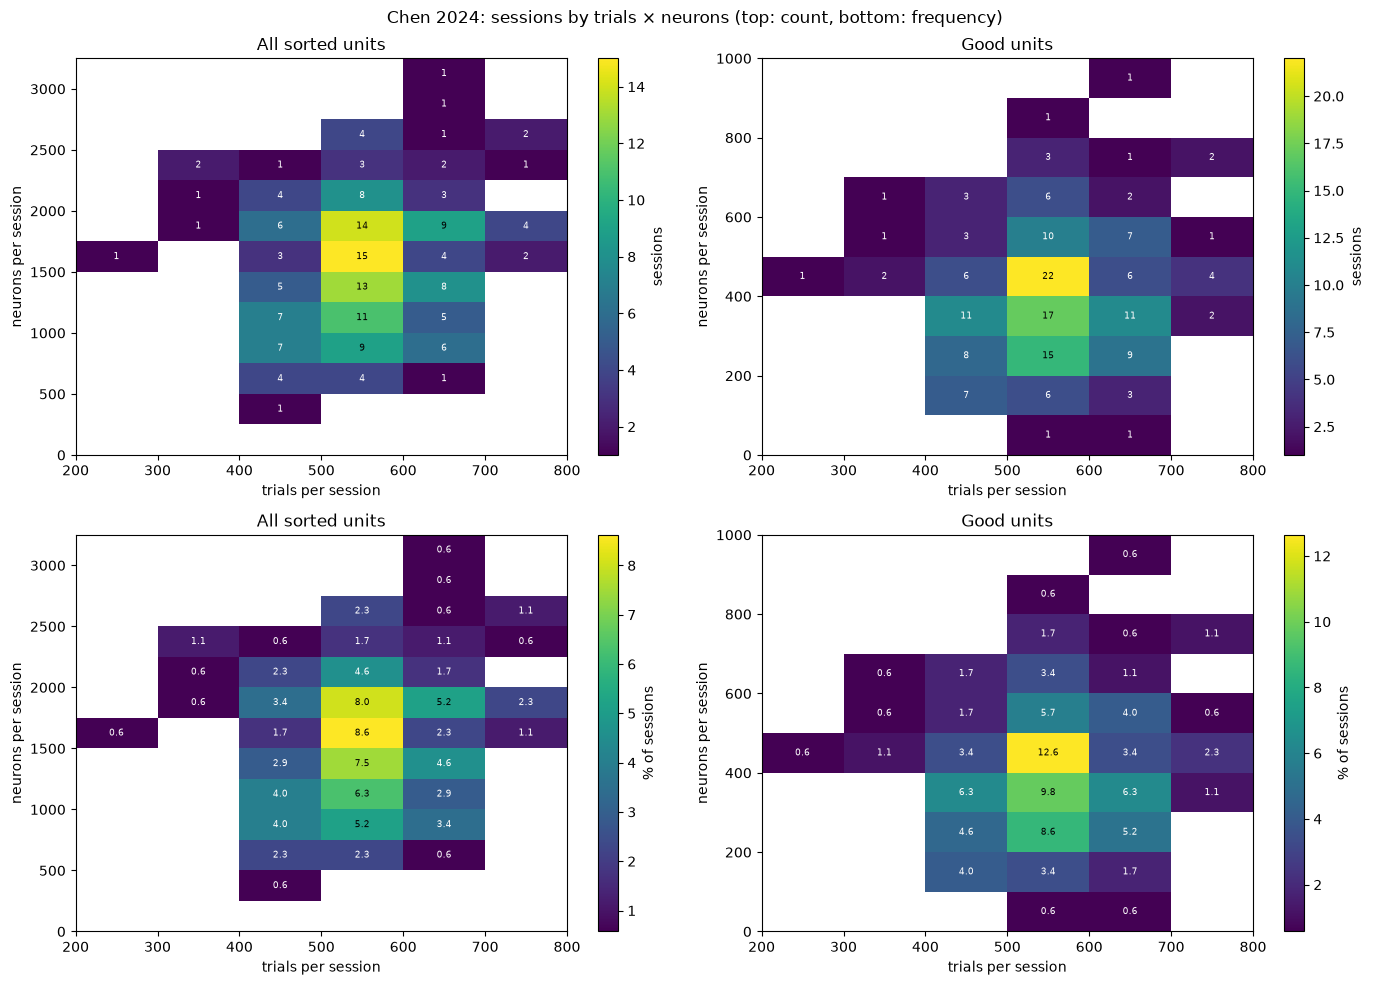

In [11]:
def heatmap(ax, x, y, xbins, ybins, percent, title):
    H, xe, ye = np.histogram2d(x, y, [xbins, ybins])
    if percent:
        H = H / len(x) * 100
    im = ax.pcolormesh(xe, ye, np.ma.masked_equal(H.T, 0), cmap="viridis", shading="flat")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            if H[i, j]:
                ax.text((xe[i] + xe[i + 1]) / 2, (ye[j] + ye[j + 1]) / 2, f"{H[i, j]:.1f}" if percent else f"{H[i, j]:.0f}",
                        ha="center", va="center", fontsize=6.5, color="w" if H[i, j] < 0.6 * H.max() else "k")
    ax.set(title=title, xlabel="trials per session", ylabel="neurons per session")
    plt.colorbar(im, ax=ax, label="% of sessions" if percent else "sessions")


tbins = np.arange(sessions.trials.min() // 100 * 100, sessions.trials.max() + 100, 100)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, percent in enumerate([False, True]):
    heatmap(axes[row, 0], sessions.trials, sessions.units, tbins, np.arange(0, sessions.units.max() + 250, 250),
            percent, "All sorted units")
    heatmap(axes[row, 1], sessions.trials, sessions.good_units, tbins,
            np.arange(0, sessions.good_units.max() + 100, 100), percent, "Good units")
fig.suptitle("Chen 2024: sessions by trials × neurons (top: count, bottom: frequency)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "chen_trials_x_neurons.png", dpi=150)
plt.show()

### Brain regions

- Each unit's CCF annotation (the NWB's `anno_name`, a CCF structure name) maps to:
  - its acronym;
  - then its region (layers merged into their parent);
  - then its major division (the same mapping as the coverage comparison).
- "outside" = fiber tracts and ventricles.
- Left: good units by division. Right: the 30 regions with the most good units.

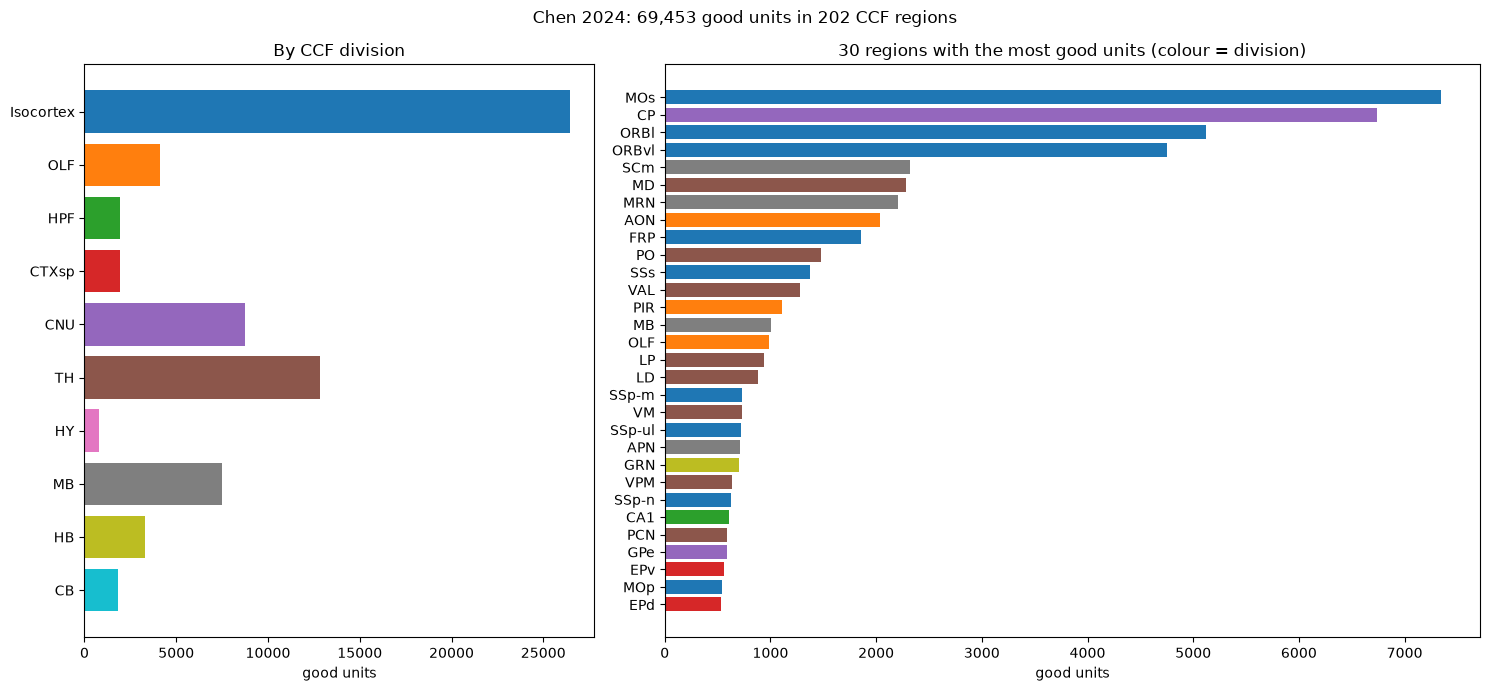

293 CCF labels -> 202 regions (layers merged); 87 regions with ≥ 100 good units. Per session: median 6 regions with ≥ 20 good units.


division,Isocortex,OLF,HPF,CTXsp,CNU,TH,HY,MB,HB,CB
sessions with ≥ 20 good units,163,58,39,17,83,71,15,89,39,17


In [12]:
DIVS = ["Isocortex", "OLF", "HPF", "CTXsp", "CNU", "TH", "HY", "MB", "HB", "CB"]
DIV_COLOR = dict(zip(DIVS + ["outside"], plt.cm.tab10.colors + ((0.6, 0.6, 0.6),)))
div = good.division.replace("", "outside").value_counts().reindex(DIVS + ["outside"]).dropna()
reg = good[good.region != ""].groupby(["region", "division"]).size().sort_values(ascending=False)
top = reg.head(30)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw=dict(width_ratios=[1, 1.6]))
axes[0].barh(np.arange(len(div))[::-1], div, color=[DIV_COLOR[d] for d in div.index])
axes[0].set(yticks=np.arange(len(div))[::-1], yticklabels=div.index, xlabel="good units", title="By CCF division")
axes[1].barh(np.arange(len(top))[::-1], top, color=[DIV_COLOR[d] for d in top.index.get_level_values(1)])
axes[1].set(yticks=np.arange(len(top))[::-1], yticklabels=top.index.get_level_values(0), xlabel="good units",
            title="30 regions with the most good units (colour = division)")
fig.suptitle(f"Chen 2024: {len(good):,} good units in {good[good.region != ''].region.nunique()} CCF regions")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "chen_regions.png", dpi=150)
plt.show()
per = good[good.region != ""].groupby(["session", "region"]).size()
print(f"{good.anno_name.nunique()} CCF labels -> {reg.index.get_level_values(0).nunique()} regions (layers merged); "
      f"{(reg >= 100).sum()} regions with ≥ 100 good units. Per session: median "
      f"{(per >= 20).groupby('session').sum().median():.0f} regions with ≥ 20 good units.")
div_sess = good[good.division != ""].groupby(["session", "division"]).size().unstack(fill_value=0)
display((div_sess >= 20).sum().reindex(DIVS).rename("sessions with ≥ 20 good units").to_frame().T)

### Raster

- Session: the one with the median number of good units. Window: 30 s, from its 11th trial.
- Rows: good units, grouped by probe and sorted by depth (deepest at the bottom of each band).
- Blue lines separate probes. The label is the probe target and its most common regions.
- Shading: sample (tone) epoch in yellow, delay in gray. Red lines: go cue.
- Below: licks.
- The blank stripes between trials are not silence: the release has no spikes there.

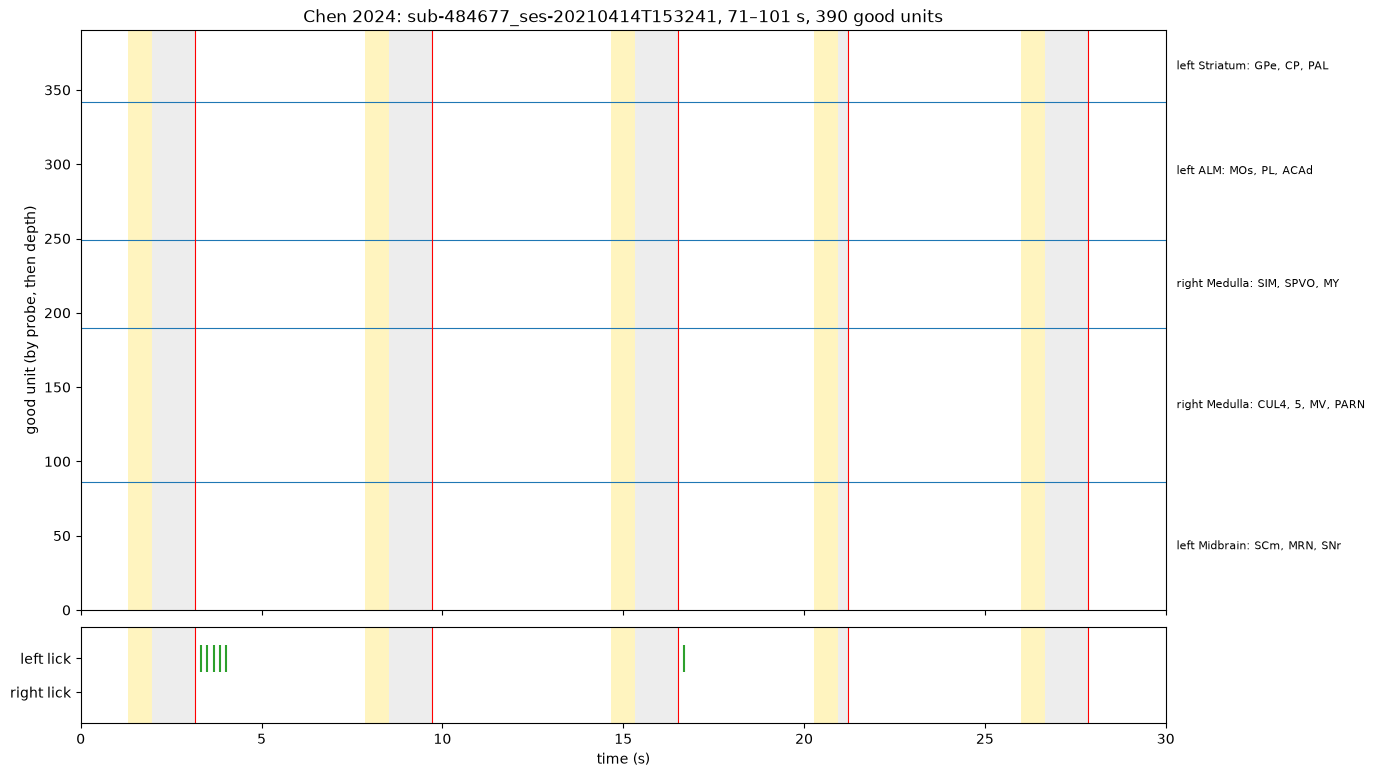

In [13]:
r = np.load(TABLES / "raster.npz", allow_pickle=True)
sess = str(r["session"])
fig, (ax, bx) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw=dict(height_ratios=[6, 1], hspace=0.05))
ax.scatter(r["spike_times"], r["spike_rows"], s=0.3, color="k", marker="|", linewidths=0.3, rasterized=True)
b = r["probe_bounds"]
for y in b[1:-1]:
    ax.axhline(y, color="C0", lw=0.8)
tgt = probes[probes.session == sess].set_index("probe").target
for k, name in enumerate(r["probe_names"]):
    regs = pd.Series(r["unit_regions"][b[k]:b[k + 1]])
    ax.text(30.3, (b[k] + b[k + 1]) / 2, f"{tgt.get(name, name)}: {', '.join(regs[regs != ''].value_counts().head(3).index)}",
            va="center", fontsize=8)
# epochs: sample = sample start -> first delay start after it; delay = that -> next go cue (repeat starts skipped)
go, end = r["go_start_times"], -1.0
for s0 in np.sort(r["sample_start_times"]):
    if s0 < end:
        continue
    d = r["delay_start_times"][r["delay_start_times"] > s0]
    d0 = d[0] if len(d) else 30.0
    g = go[go > d0]
    end = g[0] if len(g) else 30.0
    for x in (ax, bx):
        x.axvspan(s0, d0, color="gold", alpha=0.25, lw=0)
        x.axvspan(d0, end, color="0.8", alpha=0.35, lw=0)
for x in (ax, bx):
    for g in go:
        x.axvline(g, color="r", lw=0.8)
    for p in r["photostim_start_times"]:
        x.axvspan(p, p + 0.5, color="C0", alpha=0.25, lw=0)
ax.set(ylim=(0, b[-1]), ylabel="good unit (by probe, then depth)",
       title=f"Chen 2024: {sess}, {float(r['t0']):.0f}–{float(r['t0']) + 30:.0f} s, {b[-1]:,} good units")
bx.eventplot([r["left_lick_times"], r["right_lick_times"]], lineoffsets=[1, 0], colors=["C2", "C4"], linelengths=0.8)
bx.set(yticks=[1, 0], yticklabels=["left lick", "right lick"], xlabel="time (s)", xlim=(0, 30))
fig.savefig(FIGURE_DIR / "chen_raster.png", dpi=150, bbox_inches="tight")
plt.show()

## Spreadsheet

- Same columns as the NLB / FALCON / IBL / Allen / Stringer CSVs. CHANNELS = `N/A` (sorted units).
- LENGTH: 1 decimal minute. RAW / BENCHMARK: 3 decimal GB.
- This cell writes `tutorials/chen_datasets.csv`.

In [14]:
oc = trials.outcome.value_counts()
dv = good.division.value_counts()
pc = sessions.probes.value_counts().sort_index()
notes = (
    f"Chen et al. 2024 (Cell 187:676), DANDI 000363 'Mesoscale Activity Map Dataset' v0.231012.2129 (CC0): "
    f"{len(sessions)} sessions from {sessions.subject.nunique()} mice; one task (memory-guided directional licking, "
    f"'audio delay': tone instructs left / right, delay, go cue; ALM photoinhibition, left / right / both hemispheres, "
    f"last 0.5 s of the delay, on {(trials.photostim == 'photostim').sum():,} trials, hemisphere not in the trials table); {len(probes)} Neuropixels probes, 2–5 simultaneous per session "
    f"({', '.join(f'{n}: {c}' for n, c in pc.items())} sessions), targeted at ALM and connected areas. "
    f"TRIALS = every trial row ({oc['hit']:,} hit, {oc['miss']:,} miss, {oc['ignore']:,} ignore; "
    f"{(trials.early_lick == 'early').sum():,} early lick; {(trials.water != 'earned').sum():,} auto / free water). "
    f"CHANNELS N/A (sorted units). NEURONS = 'good' Kilosort2 units, labelled by the authors' curation-trained "
    f"classifiers ({sessions.good_units.sum():,}; median {sessions.good_units.median():.0f}; paper 69,943, median 393); "
    f"all sorted units {sessions.units.sum():,}. One session "
    f"(sub-440958_ses-20190216T162508) has no QC labels, so 0 good units. Regions: CCF annotation per unit, "
    f"{good[good.region != ''].region.nunique()} regions (layers merged); good units by division "
    + ", ".join(f"{d} {dv.get(d, 0):,}" for d in dv.index if d) + (f", outside {dv['']:,}" if "" in dv else "") + ". "
    f"Spikes are released only inside trials (none in the ~2 s between trials), so LENGTH = summed trial time up to "
    f"each session's last spike (first-to-last spike, gaps included: {sessions.length_min.sum():,.1f} min); in "
    f"{len(short)} sessions spikes stop more than a minute before the last trial ends ({(short.source_bytes < 1e9).sum()} "
    f"of them are the small assets with no raw voltage or video). RAW = whole dandiset, {raw_bytes / GB:,.3f} GB of NWB (compressed raw voltage, "
    f"{sessions.raw_ephys_nominal_bytes.sum() / 1e12:.1f} TB uncompressed, and per-trial face video, "
    f"{sessions.raw_video_nominal_bytes.sum() / 1e12:.1f} TB uncompressed). BENCHMARK = good-unit spike times "
    f"(8 B/spike, {spike_bytes / GB:.3f} GB) + behavioural events and jaw / nose / tongue tracking at ~294 Hz "
    f"({beh_bytes / GB:.3f} GB) + trials ({trial_bytes / GB:.3f} GB). Labels: instruction, outcome, early lick, "
    f"photostim, lick times, task epochs, orofacial tracking."
)
row = {
    "DATASET": "Chen 2024 mesoscale activity map", "ANIMAL": "Mouse", "SUBJECTS": sessions.subject.nunique(),
    "TRIALS": len(trials), "TOTAL CHANNELS": "N/A", "MEDIAN CHANNELS": "N/A",
    "TOTAL NEURONS": int(sessions.good_units.sum()), "MEDIAN NEURONS": int(sessions.good_units.median()),
    "RECORDING LENGTH (min)": round(sessions.spike_min.sum(), 1), "RAW DATASET SIZE (GB)": round(raw_bytes / GB, 3),
    "BENCHMARK DATASET SIZE (GB)": round(benchmark_bytes / GB, 3), "NOTES": notes,
    "BASIC STATS": f"firing rate (good units): mean {fr.mean():.2f}, median {fr.median():.2f} spikes/s",
}
csv = pd.DataFrame([row])
csv.to_csv(REPO / "tutorials" / "chen_datasets.csv", index=False)
display(csv.drop(columns="NOTES").T)
print(notes)

,0
DATASET,Chen 2024 mesoscale activity map
ANIMAL,Mouse
SUBJECTS,28
TRIALS,94990
TOTAL CHANNELS,N/A
MEDIAN CHANNELS,N/A
TOTAL NEURONS,69453
MEDIAN NEURONS,390
RECORDING LENGTH (min),7814.2
RAW DATASET SIZE (GB),65700.263


Chen et al. 2024 (Cell 187:676), DANDI 000363 'Mesoscale Activity Map Dataset' v0.231012.2129 (CC0): 174 sessions from 28 mice; one task (memory-guided directional licking, 'audio delay': tone instructs left / right, delay, go cue; ALM photoinhibition, left / right / both hemispheres, last 0.5 s of the delay, on 18,588 trials, hemisphere not in the trials table); 659 Neuropixels probes, 2–5 simultaneous per session (2: 2, 3: 53, 4: 99, 5: 20 sessions), targeted at ALM and connected areas. TRIALS = every trial row (65,254 hit, 15,641 miss, 14,095 ignore; 10,805 early lick; 3,766 auto / free water). CHANNELS N/A (sorted units). NEURONS = 'good' Kilosort2 units, labelled by the authors' curation-trained classifiers (69,453; median 390; paper 69,943, median 393); all sorted units 272,227. One session (sub-440958_ses-20190216T162508) has no QC labels, so 0 good units. Regions: CCF annotation per unit, 202 regions (layers merged); good units by division Isocortex 26,443, TH 12,808, CNU 8,756